In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

In [2]:
%pip install opencv-python numpy matplotlib scikit-image

Note: you may need to restart the kernel to use updated packages.


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Matplotlib version:", plt.matplotlib.__version__)
print("Scikit-image version:", skimage.__version__)

print("\nAll libraries imported successfully!")

OpenCV version: 5.0.0
NumPy version: 2.1.3
Matplotlib version: 3.10.0
Scikit-image version: 0.25.0

All libraries imported successfully!


First image loaded: True
Second image loaded: True


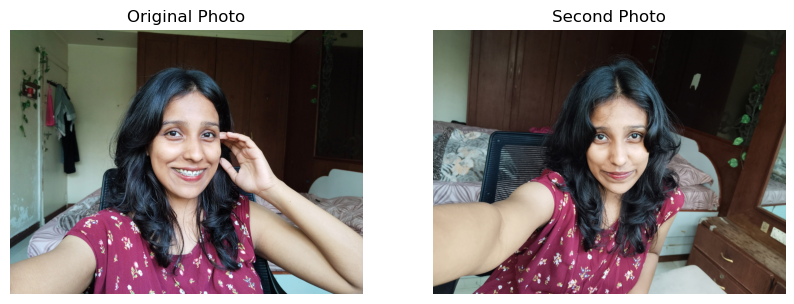

In [4]:
import cv2
import matplotlib.pyplot as plt

# Load the two photographs
img1 = cv2.imread("../input/original.jpg")
img2 = cv2.imread("../input/second.jpg")

# Check whether the images loaded
print("First image loaded:", img1 is not None)
print("Second image loaded:", img2 is not None)

# Display both photographs
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB))
plt.title("Original Photo")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
plt.title("Second Photo")
plt.axis("off")

plt.show()

In [19]:
img1 = cv2.imread("../input/original.jpg")

if img1 is None:
    print("Image not found. Check the input folder.")
else:
    image = img1.astype(np.float32) / 255.0
    print("Image loaded successfully:", image.shape)

Image loaded successfully: (3456, 4608, 3)


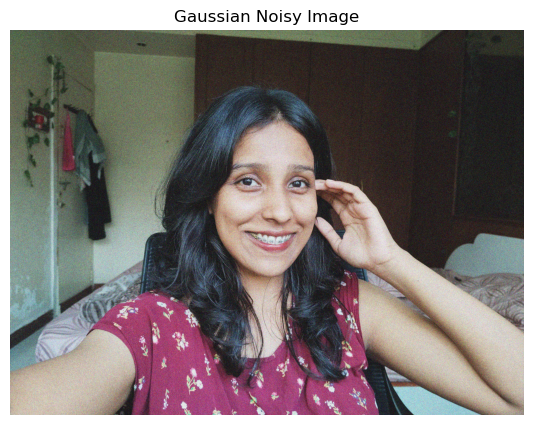

Image saved successfully: True


In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Load original image
img1 = cv2.imread("../input/original.jpg")

if img1 is None:
    print("Image not found. Check the input folder.")
else:
    image = img1.astype(np.float32) / 255.0

    # Generate Gaussian noise
    mean = 0
    sigma = 0.25
    gaussian_noise = np.random.normal(mean, sigma, image.shape)

    noisy_image = image + gaussian_noise
    noisy_image = np.clip(noisy_image, 0, 1)

    # Convert to uint8
    gaussian_noisy_uint8 = (noisy_image * 255).astype(np.uint8)

    # Save output
    os.makedirs("../outputs", exist_ok=True)
    saved = cv2.imwrite(
        "../outputs/01_gaussian_noisy.png",
        gaussian_noisy_uint8
    )

    plt.figure(figsize=(10, 5))
    plt.imshow(cv2.cvtColor(gaussian_noisy_uint8, cv2.COLOR_BGR2RGB))
    plt.title("Gaussian Noisy Image")
    plt.axis("off")
    plt.show()

    print("Image saved successfully:", saved)

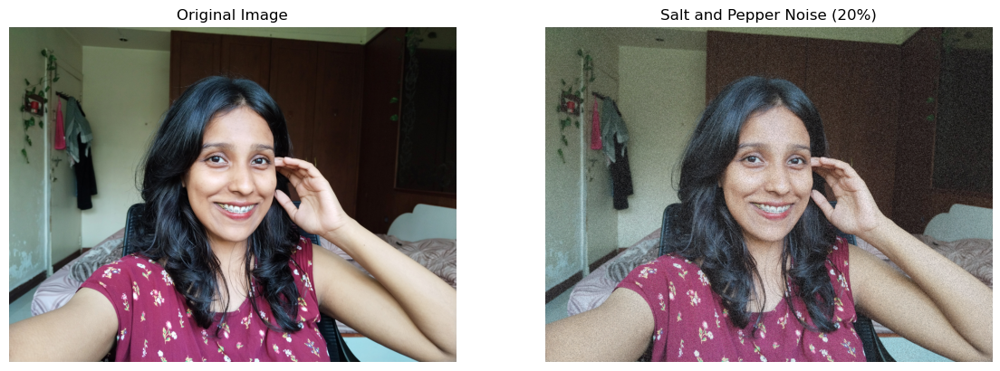

White and black noise pixels added: 3183991


True

In [22]:
# Create a fresh copy of the original image
sp_image = img1.copy()

# Increase noise probability
probability = 0.20

# Generate random values
random_values = np.random.random(img1.shape[:2])

# Add white dots (salt)
sp_image[random_values < probability / 2] = 255

# Add black dots (pepper)
sp_image[random_values > 1 - probability / 2] = 0

# Display images
plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(sp_image, cv2.COLOR_BGR2RGB))
plt.title("Salt and Pepper Noise (20%)")
plt.axis("off")

plt.show()

print("White and black noise pixels added:",
      np.sum(random_values < probability / 2) +
      np.sum(random_values > 1 - probability / 2))
cv2.imwrite("../outputs/02_salt_pepper_noisy.png", sp_image)

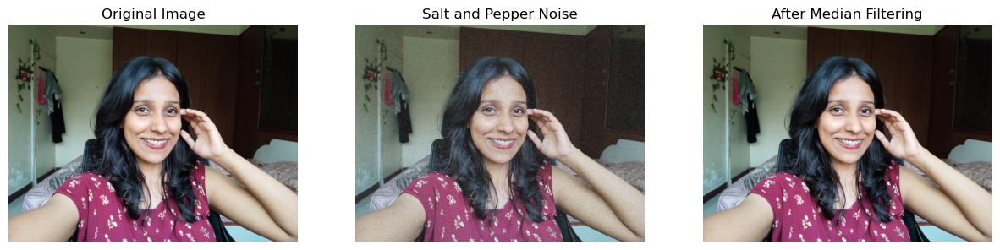

True

In [23]:
# Apply Median Filter to remove Salt-and-Pepper noise
median_filtered = cv2.medianBlur(sp_image, 5)

# Display comparison
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(sp_image, cv2.COLOR_BGR2RGB))
plt.title("Salt and Pepper Noise")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(median_filtered, cv2.COLOR_BGR2RGB))
plt.title("After Median Filtering")
plt.axis("off")

plt.show()
cv2.imwrite("../outputs/03_median_filtered.png", median_filtered)

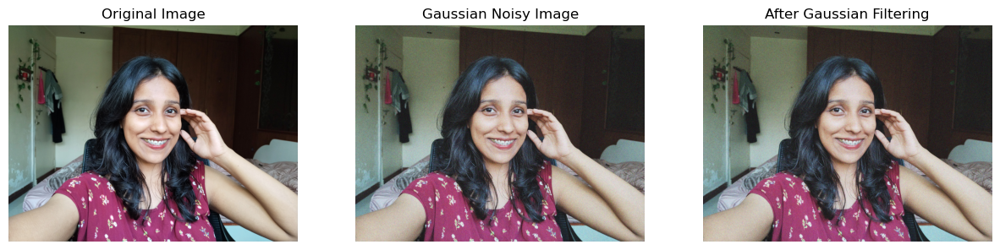

True

In [24]:
# Convert noisy Gaussian image back to 8-bit format
gaussian_noisy_uint8 = (noisy_image * 255).astype(np.uint8)

# Apply Gaussian Blur
gaussian_filtered = cv2.GaussianBlur(
    gaussian_noisy_uint8,
    (5, 5),
    0
)

# Display comparison
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(gaussian_noisy_uint8, cv2.COLOR_BGR2RGB))
plt.title("Gaussian Noisy Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(gaussian_filtered, cv2.COLOR_BGR2RGB))
plt.title("After Gaussian Filtering")
plt.axis("off")

plt.show()
cv2.imwrite("../outputs/04_gaussian_filtered.png", gaussian_filtered)

In [14]:
print("Checking image variables...")

print("Original:", img1.shape)
print("Filtered:", gaussian_filtered.shape)

print("PSNR:", peak_signal_noise_ratio(
    img1, gaussian_filtered, data_range=255
))

print("SSIM:", structural_similarity(
    img1, gaussian_filtered,
    channel_axis=2, data_range=255
))

Checking image variables...
Original: (3456, 4608, 3)
Filtered: (3456, 4608, 3)
PSNR: 22.6013385015673
SSIM: 0.3300266039889131


In [16]:
ssim_value = structural_similarity(
    img1,
    gaussian_filtered,
    channel_axis=2,
    data_range=255
)

print("SSIM:", ssim_value)

SSIM: 0.3300266039889131


In [17]:
# Calculate PSNR and SSIM for all noisy and restored images

results = {
    "Gaussian Noisy": (gaussian_noisy_uint8),
    "Gaussian Filtered": (gaussian_filtered),
    "Salt-Pepper Noisy": (sp_image),
    "Median Filtered": (median_filtered)
}

print("IMAGE QUALITY COMPARISON")
print("--------------------------------")

for name, result in results.items():
    psnr = peak_signal_noise_ratio(
        img1, result, data_range=255
    )

    ssim = structural_similarity(
        img1, result, channel_axis=2, data_range=255
    )

    print("\n", name)
    print("PSNR:", round(psnr, 3))
    print("SSIM:", round(ssim, 4))

IMAGE QUALITY COMPARISON
--------------------------------

 Gaussian Noisy
PSNR: 13.492
SSIM: 0.0565

 Gaussian Filtered
PSNR: 22.601
SSIM: 0.33

 Salt-Pepper Noisy
PSNR: 11.657
SSIM: 0.0475

 Median Filtered
PSNR: 32.212
SSIM: 0.8089


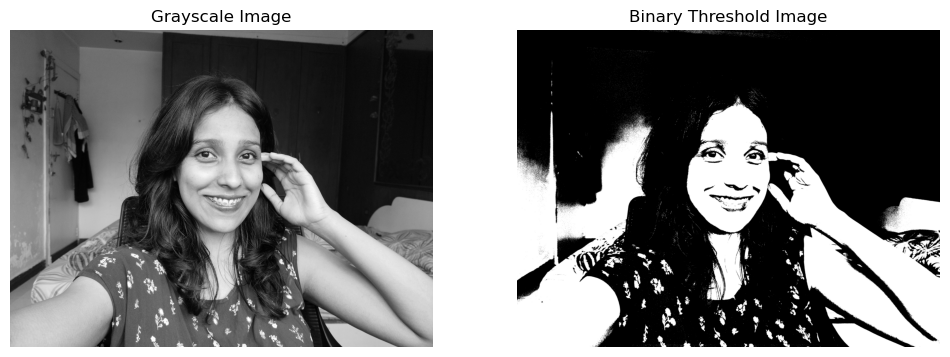

Thresholding image saved successfully: True


In [26]:
# Convert original image to grayscale
gray_image = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)

# Apply binary thresholding
threshold_value, binary_image = cv2.threshold(
    gray_image, 127, 255, cv2.THRESH_BINARY
)

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_image, cmap="gray")
plt.title("Binary Threshold Image")
plt.axis("off")

plt.show()

# Save output image
saved = cv2.imwrite(
    "../outputs/05_thresholding.png",
    binary_image
)

print("Thresholding image saved successfully:", saved)

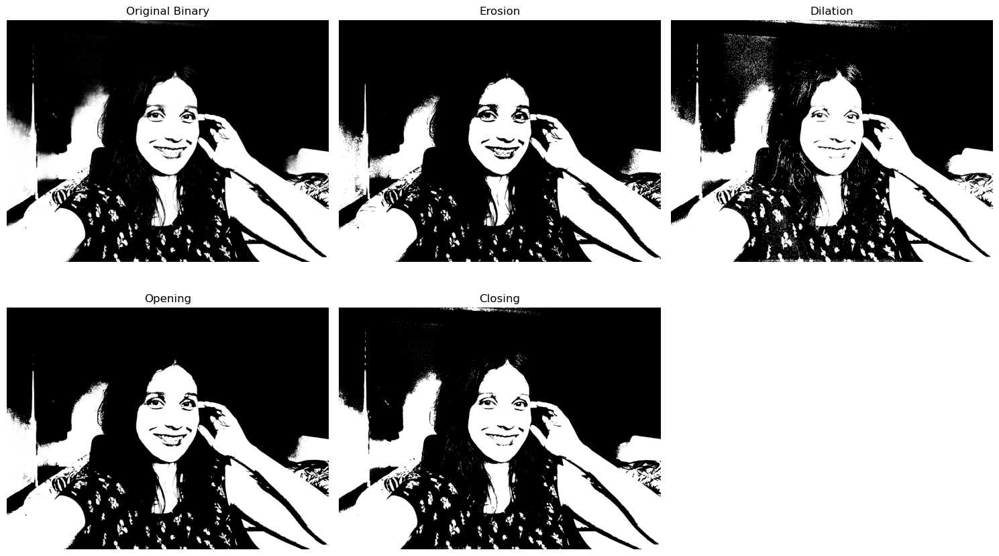

All four morphological images saved successfully!


In [27]:
# Create a structuring element (kernel)
kernel = np.ones((5, 5), np.uint8)

# Apply morphological operations
erosion = cv2.erode(binary_image, kernel, iterations=1)

dilation = cv2.dilate(binary_image, kernel, iterations=1)

opening = cv2.morphologyEx(
    binary_image, cv2.MORPH_OPEN, kernel
)

closing = cv2.morphologyEx(
    binary_image, cv2.MORPH_CLOSE, kernel
)

# Display all results
images = [
    ("Original Binary", binary_image),
    ("Erosion", erosion),
    ("Dilation", dilation),
    ("Opening", opening),
    ("Closing", closing)
]

plt.figure(figsize=(15, 9))

for i, (title, result) in enumerate(images):
    plt.subplot(2, 3, i + 1)
    plt.imshow(result, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Save all four morphological outputs
cv2.imwrite("../outputs/06_erosion.png", erosion)
cv2.imwrite("../outputs/07_dilation.png", dilation)
cv2.imwrite("../outputs/08_opening.png", opening)
cv2.imwrite("../outputs/09_closing.png", closing)

print("All four morphological images saved successfully!")

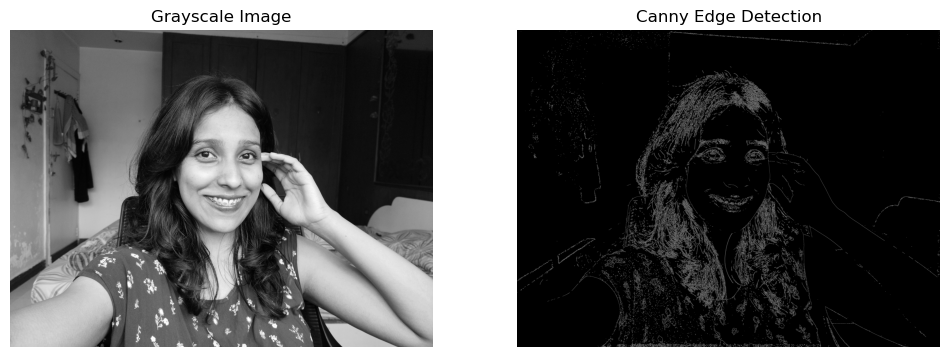

Canny edge image saved successfully: True


In [28]:
# Apply Canny Edge Detection
edges = cv2.Canny(gray_image, 100, 200)

# Display original grayscale and edge image
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.show()

# Save Canny edge output
saved = cv2.imwrite("../outputs/10_canny_edges.png", edges)

print("Canny edge image saved successfully:", saved)

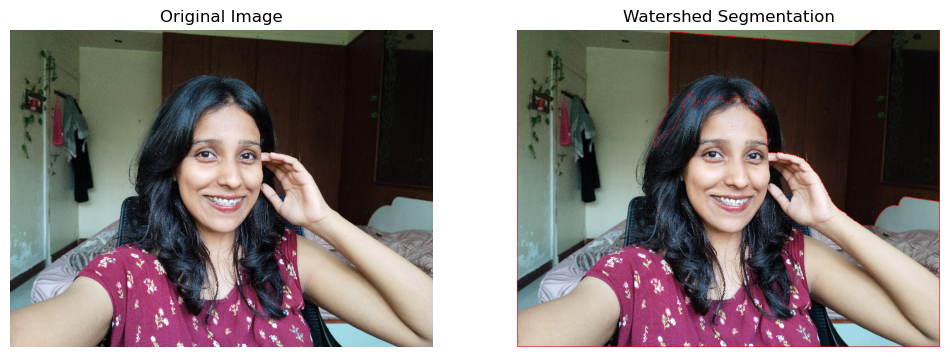

Watershed image saved successfully: True


In [29]:
# Resize image for faster Watershed processing
watershed_img = cv2.resize(img1, (800, 600))

# Create a grayscale image
gray = cv2.cvtColor(watershed_img, cv2.COLOR_BGR2GRAY)

# Apply thresholding
ret, thresh = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Remove noise using morphological opening
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(
    thresh, cv2.MORPH_OPEN, kernel, iterations=2
)

# Find sure background area
sure_bg = cv2.dilate(opening, kernel, iterations=3)

# Find sure foreground area
dist_transform = cv2.distanceTransform(
    opening, cv2.DIST_L2, 5
)

ret, sure_fg = cv2.threshold(
    dist_transform,
    0.4 * dist_transform.max(),
    255, 0
)

sure_fg = np.uint8(sure_fg)

# Find unknown region
unknown = cv2.subtract(sure_bg, sure_fg)

# Create markers
ret, markers = cv2.connectedComponents(sure_fg)

markers = markers + 1
markers[unknown == 255] = 0

# Apply Watershed
markers = cv2.watershed(watershed_img, markers)

# Mark boundaries in red
watershed_result = watershed_img.copy()
watershed_result[markers == -1] = [0, 0, 255]

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(watershed_img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(watershed_result, cv2.COLOR_BGR2RGB))
plt.title("Watershed Segmentation")
plt.axis("off")

plt.show()

# Save Watershed output
saved = cv2.imwrite(
    "../outputs/11_watershed_segmentation.png",
    watershed_result
)

print("Watershed image saved successfully:", saved)

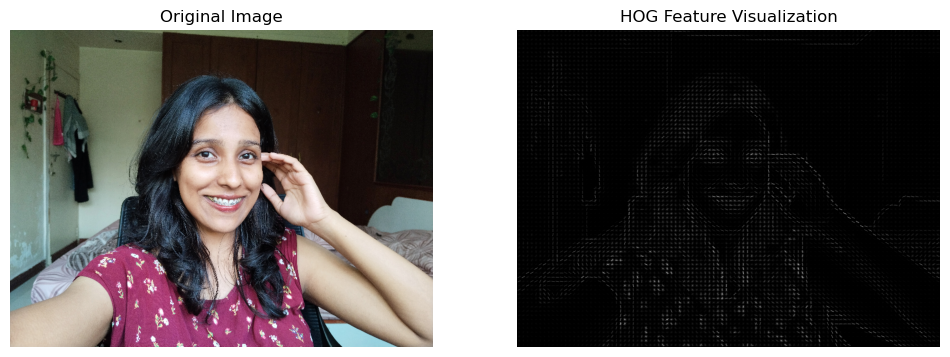

HOG feature extraction completed!
Number of HOG features: 263736
HOG image saved successfully!


In [30]:
from skimage.feature import hog

# Resize original image
hog_img = cv2.resize(img1, (800, 600))

# Convert to grayscale
gray_hog = cv2.cvtColor(hog_img, cv2.COLOR_BGR2GRAY)

# Extract HOG features
hog_features, hog_visualization = hog(
    gray_hog,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True,
    feature_vector=True
)

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(hog_img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hog_visualization, cmap="gray")
plt.title("HOG Feature Visualization")
plt.axis("off")

plt.show()

print("HOG feature extraction completed!")
print("Number of HOG features:", len(hog_features))

# Save HOG visualization
saved = plt.imsave(
    "../outputs/12_hog_visualization.png",
    hog_visualization,
    cmap="gray"
)

print("HOG image saved successfully!")

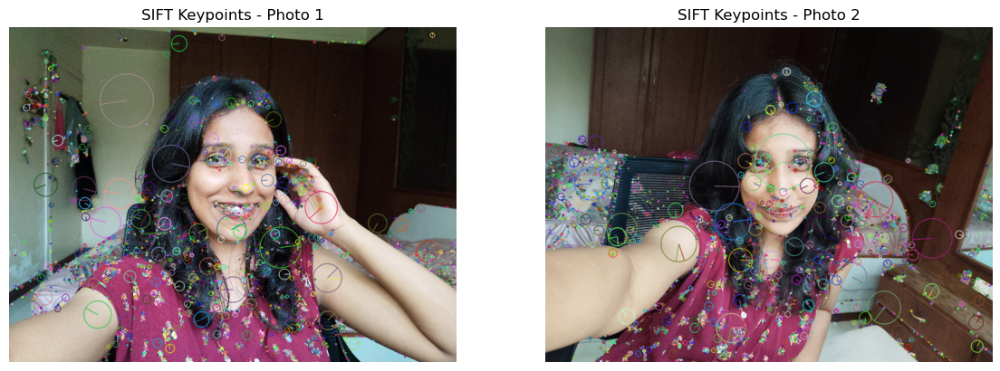

Photo 1 keypoints: 1577
Photo 2 keypoints: 1828
Photo 1 saved: True
Photo 2 saved: True


In [33]:
# Load both original images
img1 = cv2.imread("../input/original.jpg")
img2 = cv2.imread("../input/second.jpg")

if img1 is None or img2 is None:
    print("Error: Check whether both images exist in the input folder.")
else:
    # Resize both images
    sift_img1 = cv2.resize(img1, (800, 600))
    sift_img2 = cv2.resize(img2, (800, 600))

    # Convert images to grayscale
    gray1 = cv2.cvtColor(sift_img1, cv2.COLOR_BGR2GRAY)
    gray2 = cv2.cvtColor(sift_img2, cv2.COLOR_BGR2GRAY)

    # Create SIFT detector
    sift = cv2.SIFT_create()

    # Detect keypoints and descriptors
    keypoints1, descriptors1 = sift.detectAndCompute(gray1, None)
    keypoints2, descriptors2 = sift.detectAndCompute(gray2, None)

    # Draw keypoints
    sift_result1 = cv2.drawKeypoints(
        sift_img1, keypoints1, None,
        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
    )

    sift_result2 = cv2.drawKeypoints(
        sift_img2, keypoints2, None,
        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
    )

    # Display results
    plt.figure(figsize=(14, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(sift_result1, cv2.COLOR_BGR2RGB))
    plt.title("SIFT Keypoints - Photo 1")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(sift_result2, cv2.COLOR_BGR2RGB))
    plt.title("SIFT Keypoints - Photo 2")
    plt.axis("off")

    plt.show()

    print("Photo 1 keypoints:", len(keypoints1))
    print("Photo 2 keypoints:", len(keypoints2))

    # Save both images
    print("Photo 1 saved:", cv2.imwrite(
        "../outputs/13_sift_keypoints_photo1.png", sift_result1
    ))
    print("Photo 2 saved:", cv2.imwrite(
        "../outputs/14_sift_keypoints_photo2.png", sift_result2
    ))

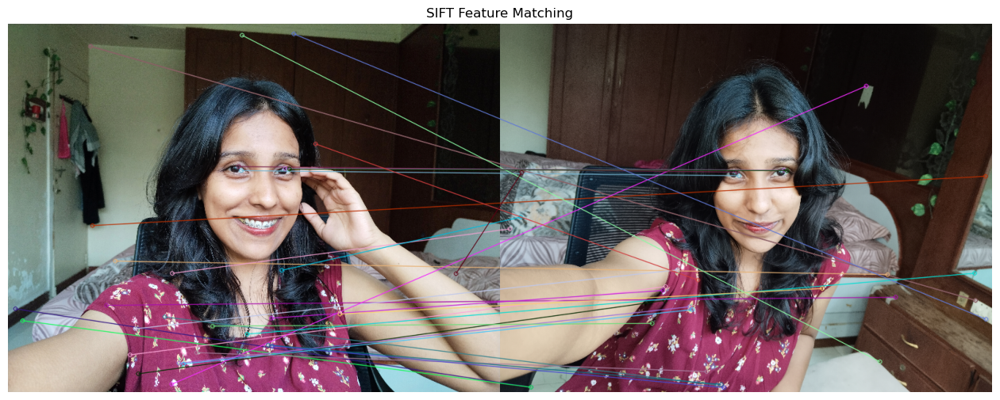

Total matches: 1577
Good matches: 31
SIFT matching image saved successfully: True


In [34]:
# Create Brute Force Matcher
bf = cv2.BFMatcher()

# Match SIFT descriptors
matches = bf.knnMatch(
    descriptors1,
    descriptors2,
    k=2
)

# Apply Lowe's ratio test
good_matches = []

for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

# Draw good matches
matching_result = cv2.drawMatches(
    sift_img1, keypoints1,
    sift_img2, keypoints2,
    good_matches[:50],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Display matching result
plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(matching_result, cv2.COLOR_BGR2RGB))
plt.title("SIFT Feature Matching")
plt.axis("off")
plt.show()

print("Total matches:", len(matches))
print("Good matches:", len(good_matches))

# Save matching result
saved = cv2.imwrite(
    "../outputs/15_sift_feature_matching.png",
    matching_result
)

print("SIFT matching image saved successfully:", saved)

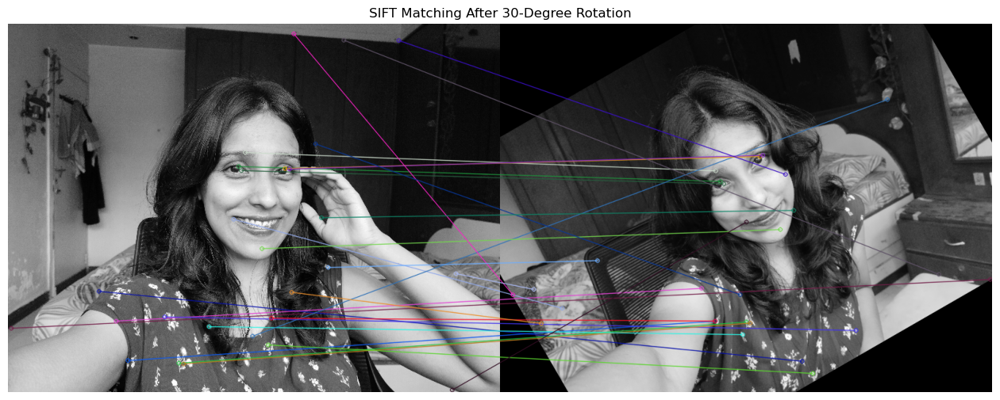

Good matches after rotation: 27
Rotation result saved successfully: True


In [35]:
# Rotate the second image by 30 degrees
height, width = gray2.shape

rotation_matrix = cv2.getRotationMatrix2D(
    (width // 2, height // 2),
    30,
    1
)

rotated_img = cv2.warpAffine(
    gray2,
    rotation_matrix,
    (width, height)
)

# Detect SIFT features in rotated image
rotated_keypoints, rotated_descriptors = sift.detectAndCompute(
    rotated_img, None
)

# Match descriptors
rotated_matches = bf.knnMatch(
    descriptors1,
    rotated_descriptors,
    k=2
)

# Apply Lowe's ratio test
rotated_good_matches = []

for m, n in rotated_matches:
    if m.distance < 0.75 * n.distance:
        rotated_good_matches.append(m)

# Draw matches
rotated_result = cv2.drawMatches(
    gray1, keypoints1,
    rotated_img, rotated_keypoints,
    rotated_good_matches[:50],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Display
plt.figure(figsize=(16, 8))
plt.imshow(rotated_result, cmap="gray")
plt.title("SIFT Matching After 30-Degree Rotation")
plt.axis("off")
plt.show()

print("Good matches after rotation:", len(rotated_good_matches))

# Save rotation experiment
saved = cv2.imwrite(
    "../outputs/16_sift_rotation_matching.png",
    rotated_result
)

print("Rotation result saved successfully:", saved)

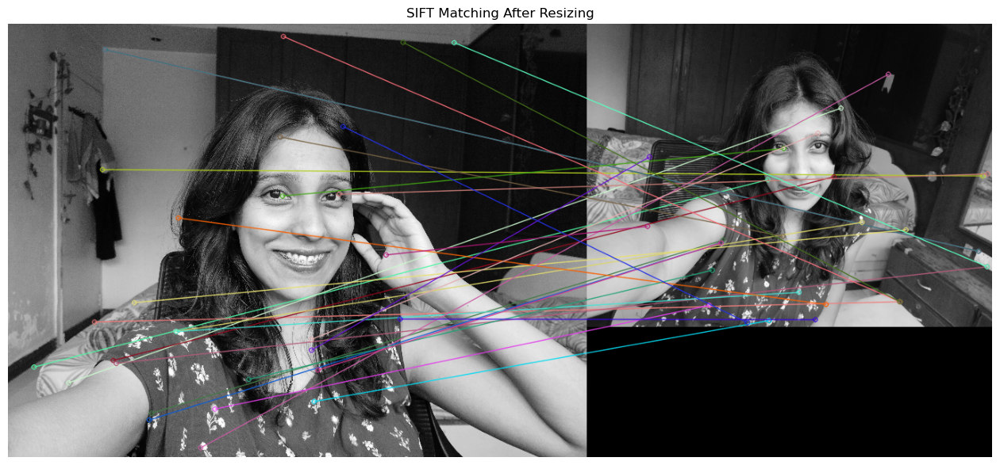

Good matches after resizing: 30
Resizing result saved successfully: True


In [36]:
# Resize the second grayscale image to 70%
resized_img = cv2.resize(
    gray2,
    None,
    fx=0.7,
    fy=0.7
)

# Detect SIFT features in resized image
resized_keypoints, resized_descriptors = sift.detectAndCompute(
    resized_img, None
)

# Match descriptors
resized_matches = bf.knnMatch(
    descriptors1,
    resized_descriptors,
    k=2
)

# Apply Lowe's ratio test
resized_good_matches = []

for m, n in resized_matches:
    if m.distance < 0.75 * n.distance:
        resized_good_matches.append(m)

# Draw feature matches
resized_result = cv2.drawMatches(
    gray1, keypoints1,
    resized_img, resized_keypoints,
    resized_good_matches[:50],
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Display result
plt.figure(figsize=(16, 8))
plt.imshow(resized_result, cmap="gray")
plt.title("SIFT Matching After Resizing")
plt.axis("off")
plt.show()

print("Good matches after resizing:", len(resized_good_matches))

# Save resizing experiment
saved = cv2.imwrite(
    "../outputs/17_sift_resizing_matching.png",
    resized_result
)

print("Resizing result saved successfully:", saved)

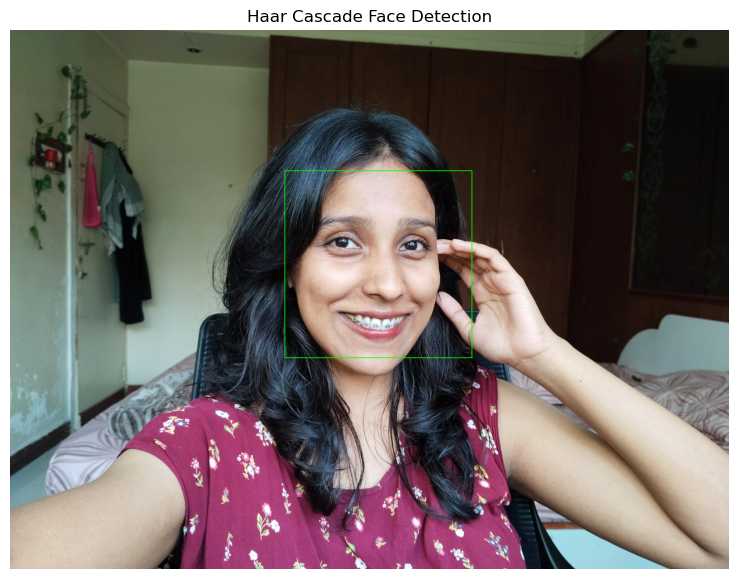

Number of faces detected: 1
Haar Cascade image saved successfully: True


In [37]:
import cv2
import matplotlib.pyplot as plt
import os

# Step 1: Load the original image
img1 = cv2.imread("../input/original.jpg")

if img1 is None:
    print("Error: Image not found. Check the image path.")

else:
    # Step 2: Load pretrained Haar Cascade face detector
    face_cascade = cv2.CascadeClassifier(
        cv2.data.haarcascades +
        "haarcascade_frontalface_default.xml"
    )

    # Step 3: Convert image to grayscale
    face_gray = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)

    # Step 4: Detect faces
    faces = face_cascade.detectMultiScale(
        face_gray,
        scaleFactor=1.1,
        minNeighbors=8,
        minSize=(80, 80)
    )

    # Step 5: Draw bounding boxes around detected faces
    face_result = img1.copy()

    for (x, y, w, h) in faces:
        cv2.rectangle(
            face_result,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            3
        )

    # Step 6: Display the detected faces
    plt.figure(figsize=(10, 7))
    plt.imshow(cv2.cvtColor(face_result, cv2.COLOR_BGR2RGB))
    plt.title("Haar Cascade Face Detection")
    plt.axis("off")
    plt.show()

    # Step 7: Print the number of detected faces
    print("Number of faces detected:", len(faces))

    # Step 8: Save the result
    os.makedirs("../outputs", exist_ok=True)

    saved = cv2.imwrite(
        "../outputs/18_haar_cascade_detection.png",
        face_result
    )

    print("Haar Cascade image saved successfully:", saved)


0: 480x640 1 person, 405.6ms
Speed: 33.0ms preprocess, 405.6ms inference, 50.1ms postprocess per image at shape (1, 3, 480, 640)


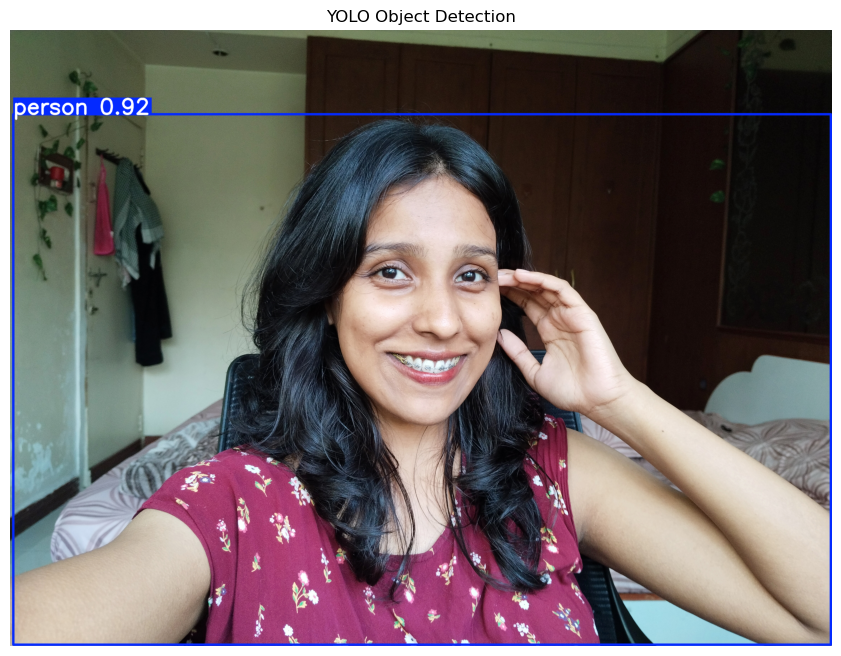

Detected Objects:
Object: person | Confidence: 91.89 %
YOLO image saved successfully: True


In [38]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
import os

# Load original image
img1 = cv2.imread("../input/original.jpg")

if img1 is None:
    print("Image not found!")

else:
    # Load pretrained YOLO model
    model = YOLO("yolov8n.pt")

    # Perform detection
    results = model(img1, conf=0.50)

    # Draw bounding boxes
    result_image = results[0].plot()

    # Display output
    plt.figure(figsize=(12, 8))
    plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
    plt.title("YOLO Object Detection")
    plt.axis("off")
    plt.show()

    # Print detected objects
    print("Detected Objects:")

    for box in results[0].boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        label = model.names[class_id]

        print("Object:", label,
              "| Confidence:", round(confidence * 100, 2), "%")

    # Save YOLO detection image
    os.makedirs("../outputs", exist_ok=True)

    saved = cv2.imwrite(
        "../outputs/19_yolo_detection.png",
        result_image
    )

    print("YOLO image saved successfully:", saved)

In [11]:
import cv2

video_path = "../input/ogvdeo.mp4"

cap = cv2.VideoCapture(video_path)

if cap.isOpened():
    print("Video loaded successfully!")

    fps = cap.get(cv2.CAP_PROP_FPS)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    print("FPS:", fps)
    print("Total frames:", total_frames)
    print("Duration:", round(total_frames / fps, 2), "seconds")

    cap.release()
else:
    print("Video could not be loaded.")

Video loaded successfully!
FPS: 29.619718309859156
Total frames: 701
Duration: 23.67 seconds


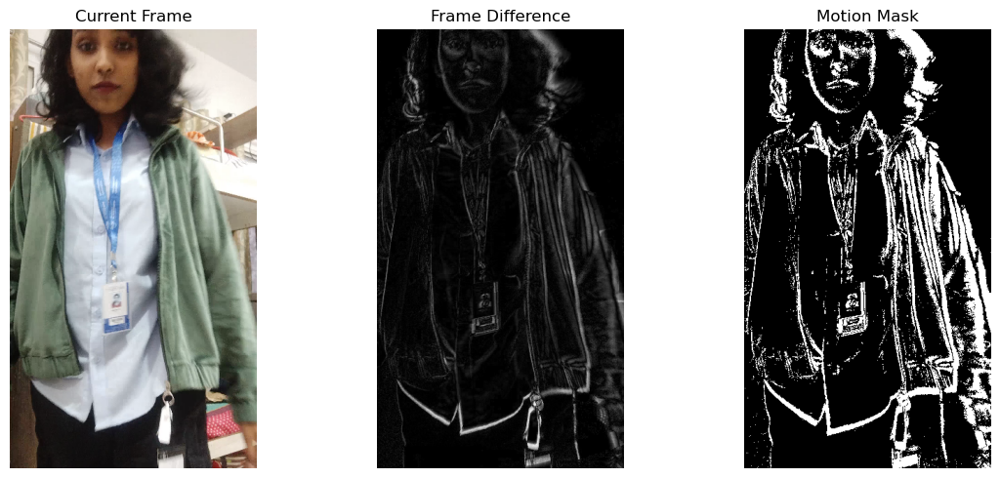

Current frame saved: True
Frame difference saved: True
Motion mask saved: True


In [39]:
import cv2
import matplotlib.pyplot as plt
import os

video_path = "../input/ogvdeo.mp4"
cap = cv2.VideoCapture(video_path)

ret, previous_frame = cap.read()

if not ret:
    print("Could not read video frames.")
else:
    previous_frame = cv2.resize(previous_frame, (360, 640))
    previous_gray = cv2.cvtColor(previous_frame, cv2.COLOR_BGR2GRAY)

    # Read the next frame
    ret, current_frame = cap.read()

    if ret:
        current_frame = cv2.resize(current_frame, (360, 640))
        current_gray = cv2.cvtColor(current_frame, cv2.COLOR_BGR2GRAY)

        # Calculate difference between consecutive frames
        frame_difference = cv2.absdiff(previous_gray, current_gray)

        # Create a binary motion mask
        _, motion_mask = cv2.threshold(
            frame_difference, 25, 255, cv2.THRESH_BINARY
        )

        # Display results
        plt.figure(figsize=(12, 5))

        plt.subplot(1, 3, 1)
        plt.imshow(cv2.cvtColor(current_frame, cv2.COLOR_BGR2RGB))
        plt.title("Current Frame")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(frame_difference, cmap="gray")
        plt.title("Frame Difference")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(motion_mask, cmap="gray")
        plt.title("Motion Mask")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

        # Save all three outputs
        os.makedirs("../outputs", exist_ok=True)

        print("Current frame saved:", cv2.imwrite(
            "../outputs/20_frame_differencing_original.png",
            current_frame
        ))

        print("Frame difference saved:", cv2.imwrite(
            "../outputs/21_frame_difference.png",
            frame_difference
        ))

        print("Motion mask saved:", cv2.imwrite(
            "../outputs/22_frame_difference_mask.png",
            motion_mask
        ))

    cap.release()

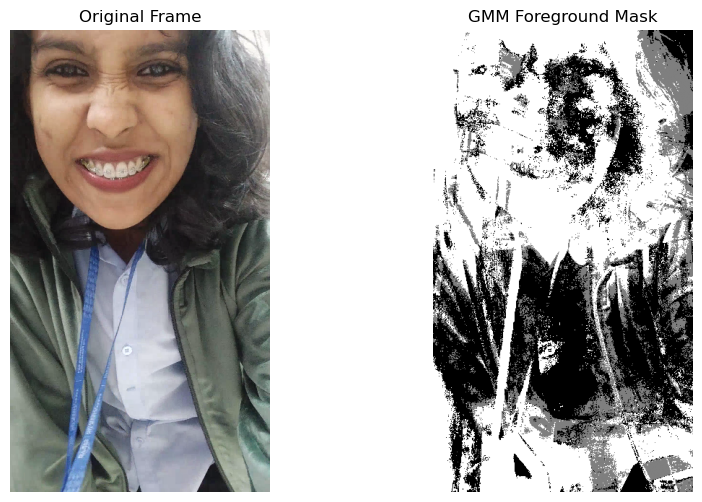

Original frame saved: True
GMM mask saved: True
Frames processed: 701


In [41]:
import cv2
import matplotlib.pyplot as plt
import os

video_path = "../input/ogvdeo.mp4"
cap = cv2.VideoCapture(video_path)

background_subtractor = cv2.createBackgroundSubtractorMOG2(
    history=500,
    varThreshold=25,
    detectShadows=True
)

frame_count = 0
foreground_mask = None
display_frame = None

while True:
    ret, frame = cap.read()

    if not ret:
        break

    frame = cv2.resize(frame, (360, 640))
    foreground_mask = background_subtractor.apply(frame)

    display_frame = frame.copy()
    frame_count += 1

cap.release()

if display_frame is not None:
    # Display results
    plt.figure(figsize=(10, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(display_frame, cv2.COLOR_BGR2RGB))
    plt.title("Original Frame")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(foreground_mask, cmap="gray")
    plt.title("GMM Foreground Mask")
    plt.axis("off")

    plt.show()

    # Save outputs
    os.makedirs("../outputs", exist_ok=True)

    print("Original frame saved:", cv2.imwrite(
        "../outputs/23_gmm_original_frame.png",
        display_frame
    ))

    print("GMM mask saved:", cv2.imwrite(
        "../outputs/24_gmm_foreground_mask.png",
        foreground_mask
    ))

    print("Frames processed:", frame_count)

else:
    print("No video frames were processed.")

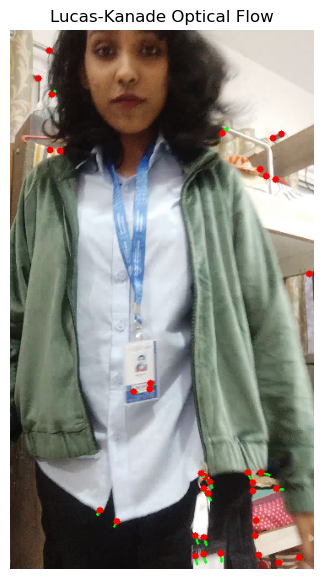

Lucas-Kanade image saved successfully: True
Number of tracked points: 37


In [42]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Load video
video_path = "../input/ogvdeo.mp4"
cap = cv2.VideoCapture(video_path)

# Read first frame
ret, old_frame = cap.read()

if not ret:
    print("Could not read video.")
else:
    old_frame = cv2.resize(old_frame, (360, 640))
    old_gray = cv2.cvtColor(old_frame, cv2.COLOR_BGR2GRAY)

    # Detect good feature points
    feature_params = dict(
        maxCorners=100,
        qualityLevel=0.3,
        minDistance=7,
        blockSize=7
    )

    p0 = cv2.goodFeaturesToTrack(
        old_gray, mask=None, **feature_params
    )

    # Read next frame
    ret, new_frame = cap.read()

    if ret:
        new_frame = cv2.resize(new_frame, (360, 640))
        new_gray = cv2.cvtColor(new_frame, cv2.COLOR_BGR2GRAY)

        # Lucas-Kanade optical flow parameters
        lk_params = dict(
            winSize=(15, 15),
            maxLevel=2,
            criteria=(
                cv2.TERM_CRITERIA_EPS |
                cv2.TERM_CRITERIA_COUNT,
                10,
                0.03
            )
        )

        # Calculate optical flow
        p1, status, error = cv2.calcOpticalFlowPyrLK(
            old_gray, new_gray, p0, None, **lk_params
        )

        # Draw motion vectors
        result = new_frame.copy()

        good_new = p1[status == 1]
        good_old = p0[status == 1]

        for new, old in zip(good_new, good_old):
            a, b = new.ravel()
            c, d = old.ravel()

            cv2.arrowedLine(
                result,
                (int(c), int(d)),
                (int(a), int(b)),
                (0, 255, 0),
                2
            )

            cv2.circle(
                result,
                (int(a), int(b)),
                4,
                (0, 0, 255),
                -1
            )

        # Display result
        plt.figure(figsize=(10, 7))
        plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
        plt.title("Lucas-Kanade Optical Flow")
        plt.axis("off")
        plt.show()

        # Save result
        os.makedirs("../outputs", exist_ok=True)

        saved = cv2.imwrite(
            "../outputs/25_lucas_kanade_optical_flow.png",
            result
        )

        print("Lucas-Kanade image saved successfully:", saved)
        print("Number of tracked points:", len(good_new))

    cap.release()